<div align="center">
<h1> Machine Learning  (S1-26_AIMLZG565) </h1>
<h2>Assignment 2</h2>
<h2>Classification Models & Evaluation</h2>
</div>

In [55]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import os

import joblib

import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, classification_report)

import seaborn as sns


RANDOM_SEED = 42

**Problem statement:** Predict whether a breast tumour is *malignant* or *benign* from 30 numeric features computed from digitised images of fine-needle aspirates. Five classifiers (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM) are trained on the same data and compared on Accuracy, AUC, Precision, Recall, F1 and MCC.

**Dataset:** Breast Cancer Wisconsin (Diagnostic) – UCI repository. Data downloaded using https://archive.ics.uci.edu/static/public/17/breast+cancer+wisconsin+diagnostic.zip. 569 instances, 30 features (minimum required: 500 / 12). 

Loading the breast cancer data from sklearn dataset 



In [39]:
#Data downloaded and placed in the directory.

"""checking the wdbc.names file to understand the columns in the wdbc.data file since wdbc.data file doesn't have column headers"""

with open("breast+cancer+wisconsin+diagnostic/wdbc.names", "r") as f:
    print(f.read())

1. Title: Wisconsin Diagnostic Breast Cancer (WDBC)

2. Source Information

a) Creators: 

	Dr. William H. Wolberg, General Surgery Dept., University of
	Wisconsin,  Clinical Sciences Center, Madison, WI 53792
	wolberg@eagle.surgery.wisc.edu

	W. Nick Street, Computer Sciences Dept., University of
	Wisconsin, 1210 West Dayton St., Madison, WI 53706
	street@cs.wisc.edu  608-262-6619

	Olvi L. Mangasarian, Computer Sciences Dept., University of
	Wisconsin, 1210 West Dayton St., Madison, WI 53706
	olvi@cs.wisc.edu 

b) Donor: Nick Street

c) Date: November 1995

3. Past Usage:

first usage:

	W.N. Street, W.H. Wolberg and O.L. Mangasarian 
	Nuclear feature extraction for breast tumor diagnosis.
	IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science
	and Technology, volume 1905, pages 861-870, San Jose, CA, 1993.

OR literature:

	O.L. Mangasarian, W.N. Street and W.H. Wolberg. 
	Breast cancer diagnosis and prognosis via linear programming. 
	Operations Research, 43(4), pag

In [40]:
"""As seen in the decsription of wdbc.names file ID and Diagnosis fields are present and then for rest of the a) to j) fields 3 variations
mean, standard error and worst computed fields are present. Hence adding the feature_headers below"""

feature_headers = ["ID", "Diagnosis", 
                   "radius_mean", "texture_mean", "perimeter_mean", "area_mean", 
                   "smoothness_mean", "compactness_mean", "concavity_mean", 
                   "concave_points_mean", "symmetry_mean", "fractal_dimension_mean", 
                   "radius_se", "texture_se", "perimeter_se", "area_se", 
                   "smoothness_se", "compactness_se", "concavity_se", 
                   "concave_points_se", "symmetry_se", "fractal_dimension_se", 
                   "radius_worst", "texture_worst", "perimeter_worst", "area_worst", 
                   "smoothness_worst", "compactness_worst", "concavity_worst", 
                   "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"]

# read the file by passing the headers names = feature_headers
data = pd.read_csv(
    "breast+cancer+wisconsin+diagnostic/wdbc.data", 
    header=None, 
    names=feature_headers, 
    skipinitialspace=True
)

#displaying the sample dataset to reconfirm that columns are mapped correctly. 
data.head(10)

#n_samples = data.shape[0]      # Total number of rows
#n_features = data.shape[1] - 2     # Number of features (excluding target)
#print(n_samples)
#print(n_features)

,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
5,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440
6,844359,M,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368
7,84458202,M,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510
8,844981,M,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720
9,84501001,M,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750


In [41]:
n_samples = data.shape[0]   
#569 rows   # Total number of rows 

n_features = data.shape[1] - 2   
#30 features  # Number of features (excluding target and ID field)

print(f"Samples: {n_samples}, Features: {n_features}")


Samples: 569, Features: 30


## Data Preprocessing

Preprocess your data:
1. Handle missing values
2. Encode categorical variables
3. Split into train/test sets
4. Scale features

In [42]:

"""
1. Seperating featuers (X) and target Y. 
The ID field doesn't hold any value in the prediction. Hence dropping it.
2. There are no missing values in the dataset.
3. All are continuous values. So no encoding needed 
4. Only the target is having M and B instead of 1 and 0. That is converted"""

#Verifying that there is no null data.
print(data.isnull().sum().sum(), "missing values")

print(data["Diagnosis"].value_counts())

data.describe().T.head(10)




0 missing values
Diagnosis
B    357
M    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
ID,569.0,3.037183e+07,1.250206e+08,8670.00000,869218.00000,906024.00000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.98100,11.70000,13.37000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.71000,16.17000,18.84000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.79000,75.17000,86.24000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.50000,420.30000,551.10000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.05263,0.08637,0.09587,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.01938,0.06492,0.09263,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.00000,0.02956,0.06154,1.307000e-01,4.268000e-01
concave_points_mean,569.0,4.891915e-02,3.880284e-02,0.00000,0.02031,0.03350,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.10600,0.16190,0.17920,1.957000e-01,3.040000e-01


#### Plotting correlation 

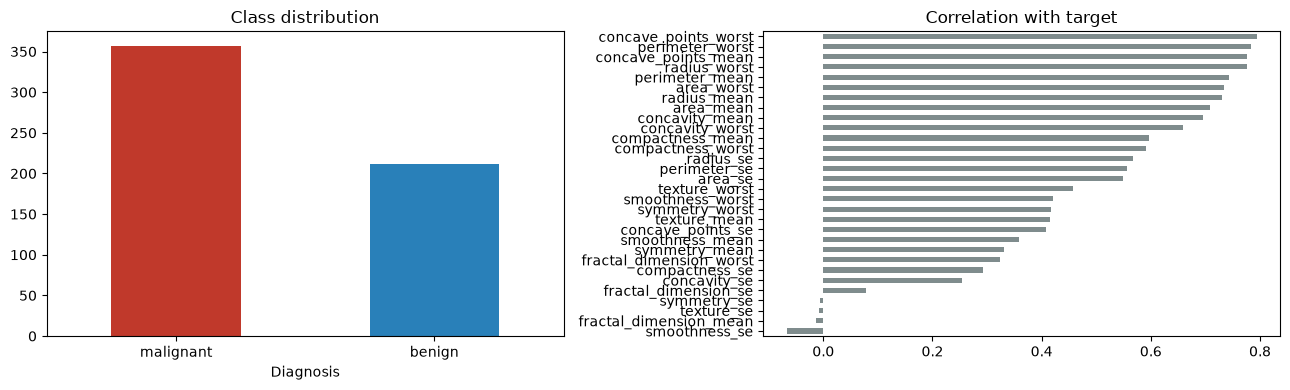

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
data["Diagnosis"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color=["#c0392b", "#2980b9"])
ax[0].set_title("Class distribution"); ax[0].set_xticklabels(["malignant", "benign"], rotation=0)
target = data["Diagnosis"].map({"B": 0, "M": 1})

#dropping ID and Diagnosis columns, ID column doesn't add any value
corr_with_target = data.drop(columns=["ID", "Diagnosis"]).corrwith(target).sort_values()
corr_with_target.plot(kind="barh", ax=ax[1], color="#7f8c8d")
ax[1].set_title("Correlation with target")
plt.tight_layout(); plt.show()

In [44]:
#Separating features X and Y
X = data.drop(["Diagnosis", "ID"], axis=1)
y = data["Diagnosis"]

#converting B and M indicators to 0 and 1 since B and M will not work with ML algorithms directly.
y = y.map({'B': 0, 'M': 1})


# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#size of split
train_sample_size = X_train.shape[0]
test_sample_size = X_test.shape[0]
ratio = train_sample_size/X.shape[0]
#print(train_sample_size,test_sample_size,ratio)

# Fill these after preprocessing
train_samples = train_sample_size       # Number of training samples
test_samples = test_sample_size        # Number of test samples
train_test_ratio = 0.8  # e.g., 0.8 for 80-20 split

print(f"Train samples: {train_samples}")
print(f"Test samples: {test_samples}")
print(f"Split ratio: {train_test_ratio:.1%}")


Train samples: 455
Test samples: 114
Split ratio: 80.0%


In [45]:
# creating test_data.csv file

test_df = X_test.copy(); test_df["Diagnosis"] = y_test
test_df.to_csv("test_data.csv", index=False)
print("Saved test_data.csv")
test_df.head(10)

Saved test_data.csv


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,Diagnosis
204,12.47,18.60,81.09,481.9,0.09965,0.10580,0.08005,0.03821,0.1925,0.06373,...,24.64,96.05,677.9,0.14260,0.2378,0.2671,0.10150,0.3014,0.08750,0
70,18.94,21.31,123.60,1130.0,0.09009,0.10290,0.10800,0.07951,0.1582,0.05461,...,26.58,165.90,1866.0,0.11930,0.2336,0.2687,0.17890,0.2551,0.06589,1
131,15.46,19.48,101.70,748.9,0.10920,0.12230,0.14660,0.08087,0.1931,0.05796,...,26.00,124.90,1156.0,0.15460,0.2394,0.3791,0.15140,0.2837,0.08019,1
431,12.40,17.68,81.47,467.8,0.10540,0.13160,0.07741,0.02799,0.1811,0.07102,...,22.91,89.61,515.8,0.14500,0.2629,0.2403,0.07370,0.2556,0.09359,0
540,11.54,14.44,74.65,402.9,0.09984,0.11200,0.06737,0.02594,0.1818,0.06782,...,19.68,78.78,457.8,0.13450,0.2118,0.1797,0.06918,0.2329,0.08134,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.8681,0.9387,0.26500,0.4087,0.12400,1
369,22.01,21.90,147.20,1482.0,0.10630,0.19540,0.24480,0.15010,0.1824,0.06140,...,25.80,195.00,2227.0,0.12940,0.3885,0.4756,0.24320,0.2741,0.08574,1
29,17.57,15.05,115.00,955.1,0.09847,0.11570,0.09875,0.07953,0.1739,0.06149,...,19.52,134.90,1227.0,0.12550,0.2812,0.2489,0.14560,0.2756,0.07919,1
81,13.34,15.86,86.49,520.0,0.10780,0.15350,0.11690,0.06987,0.1942,0.06902,...,23.19,96.66,614.9,0.15360,0.4791,0.4858,0.17080,0.3527,0.10160,0
477,13.90,16.62,88.97,599.4,0.06828,0.05319,0.02224,0.01339,0.1813,0.05536,...,21.80,101.20,718.9,0.09384,0.2006,0.1384,0.06222,0.2679,0.07698,0


## Models
Training different models

In [49]:
models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_SEED),
    "KNN": Pipeline([("scaler", StandardScaler()),
                     ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": Pipeline([("scaler", StandardScaler()),
                                        ("clf", CalibratedClassifierCV(SVC(kernel="rbf", random_state=RANDOM_SEED), ensemble=False))])

}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"trained: {name}")

trained: Logistic Regression
trained: Decision Tree
trained: KNN
trained: Naive Bayes
trained: Support Vector Machine


## Evaluation (Accuracy, AUC Score, Precision, Recall, F1 Score, Matthews Correlation Coefficient (MCC Score))

In [50]:
def evaluate(model, X, y):
    y_pred = model.predict(X) #predicting the model
    y_prob = model.predict_proba(X)[:, 1] # getting the probability of class 1 hence using [:, 1] to get second column of 2D array
    return {
        "Accuracy":  accuracy_score(y, y_pred),
        "AUC":       roc_auc_score(y, y_prob),
        "Precision": precision_score(y, y_pred),
        "Recall":    recall_score(y, y_pred),
        "F1":        f1_score(y, y_pred),
        "MCC":       matthews_corrcoef(y, y_pred)
    }

results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in models.items()}).T
results.index.name = "ML Model Name"
results.round(4)

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9737,0.9974,0.9762,0.9535,0.9647,0.9439
Decision Tree,0.9474,0.9355,0.9302,0.9302,0.9302,0.8880
KNN,0.9474,0.9820,0.9302,0.9302,0.9302,0.8880
Naive Bayes,0.9737,0.9984,1.0000,0.9302,0.9639,0.9447
Support Vector Machine,0.9561,0.9974,0.9318,0.9535,0.9425,0.9072


#### Creating a bar chart to compare the model performance on test set

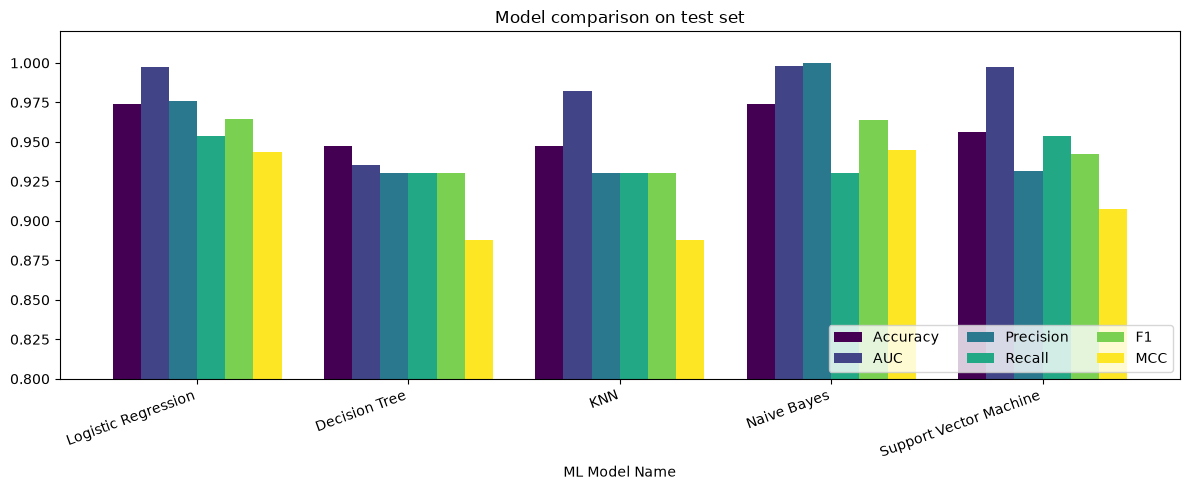

In [51]:
results.plot(kind="bar", figsize=(12, 5), colormap="viridis", width=0.8)
plt.title("Model comparison on test set"); plt.ylim(0.8, 1.02)
plt.xticks(rotation=20, ha="right"); plt.legend(loc="lower right", ncol=3)
plt.tight_layout(); plt.show()

### Confusion matrices & classification reports

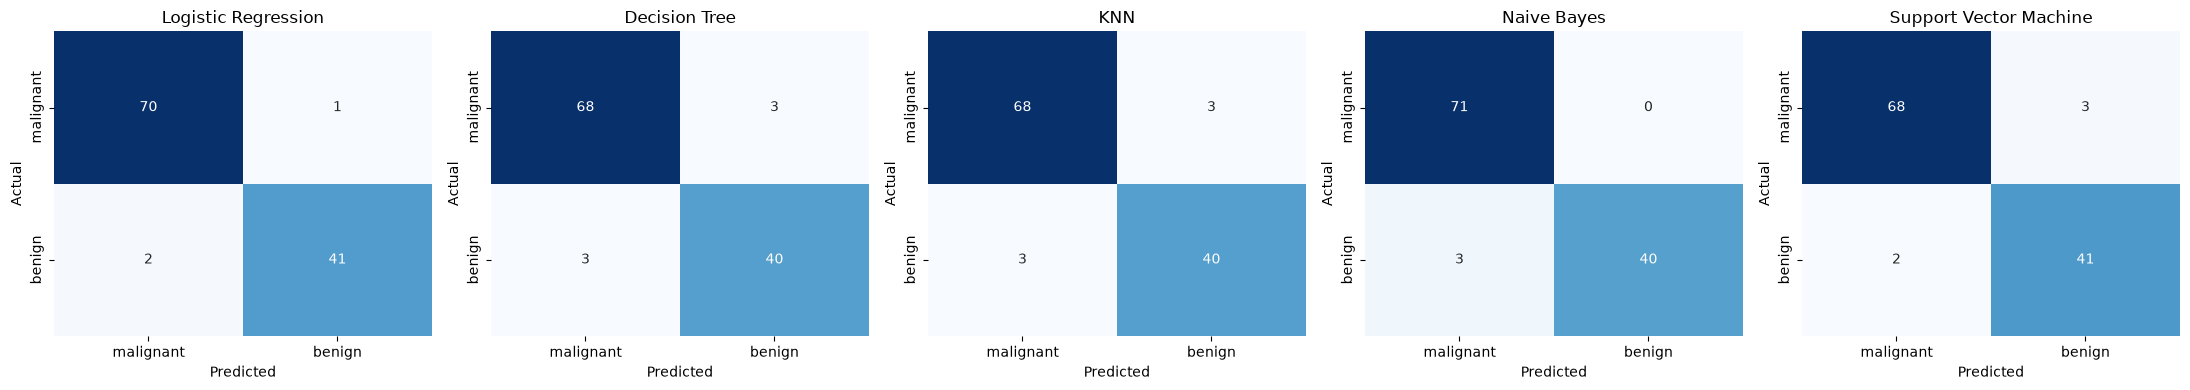

===== Logistic Regression =====
              precision    recall  f1-score   support

   malignant       0.97      0.99      0.98        71
      benign       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114

===== Decision Tree =====
              precision    recall  f1-score   support

   malignant       0.96      0.96      0.96        71
      benign       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

===== KNN =====
              precision    recall  f1-score   support

   malignant       0.96      0.96      0.96        71
      benign       0.93      0.93      0.93        43

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114


In [54]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, m) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["malignant", "benign"], yticklabels=["malignant", "benign"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

for name, m in models.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, m.predict(X_test), target_names=["malignant", "benign"]))

## Saving the trained model

In [56]:
#One `.joblib` file per classifier in `model/`; the Streamlit app loads these and evaluates on the uploaded test CSV without retraining.

os.makedirs("model", exist_ok=True)
for name, m in models.items():
    fname = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(m, os.path.join("model", fname))
    print("saved", fname)

results.round(4).to_csv("model/metrics_summary.csv")
sorted(os.listdir("model"))

saved logistic_regression.joblib
saved decision_tree.joblib
saved knn.joblib
saved naive_bayes.joblib
saved support_vector_machine.joblib


['decision_tree.joblib',
 'knn.joblib',
 'logistic_regression.joblib',
 'metrics_summary.csv',
 'naive_bayes.joblib',
 'support_vector_machine.joblib']

In [58]:
#Verifying the saved model using test_data.csv

loaded = joblib.load("model/support_vector_machine.joblib")
t = pd.read_csv("test_data.csv")
print(evaluate(loaded, t.drop(columns=["Diagnosis"]), t["Diagnosis"]))

{'Accuracy': 0.956140350877193, 'AUC': 0.99737962659679, 'Precision': 0.9318181818181818, 'Recall': 0.9534883720930233, 'F1': 0.9425287356321839, 'MCC': 0.9072320103372488}
